In [352]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import linear_model
from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.utils import resample
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

In [353]:
df=pd.read_csv('./insurance.csv')
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [354]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [355]:
df.shape

(1338, 7)

In [356]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [357]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


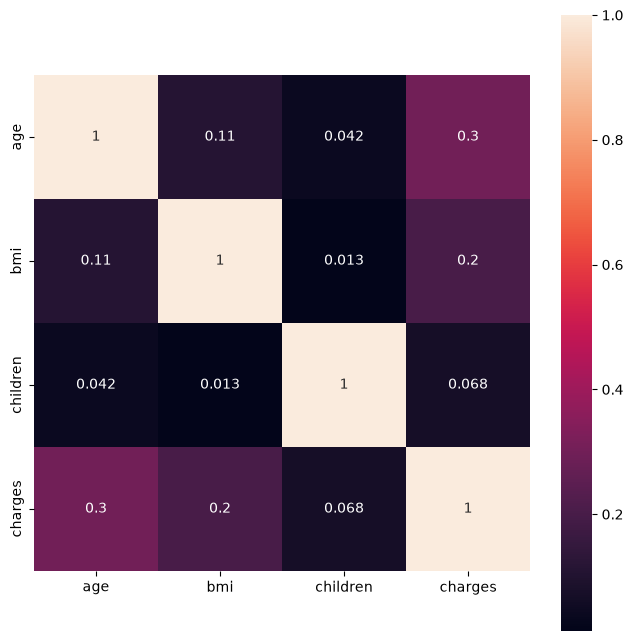

In [358]:
corr_matrix = df.corr(method='pearson', numeric_only=True)
plt.figure(figsize = (8, 8))
sns.heatmap(data=corr_matrix, square=True , annot=True, cbar=True)
plt.show()

<Axes: xlabel='smoker', ylabel='charges'>

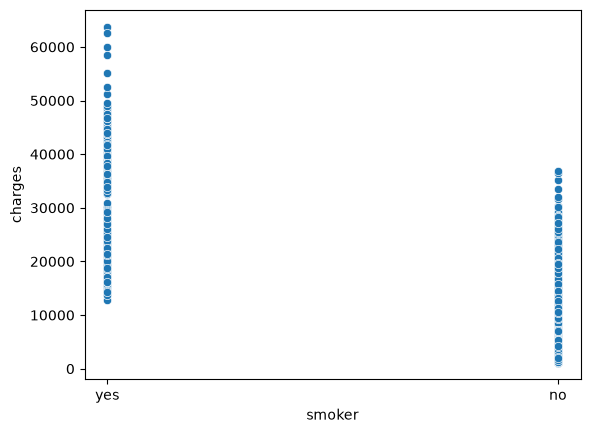

In [359]:
sns.scatterplot(x=df.smoker, y=df.charges)

<Axes: xlabel='region', ylabel='smoker'>

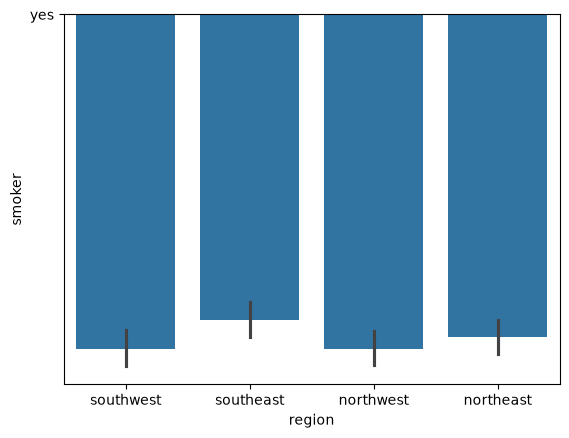

In [360]:
sns.barplot(x="region", y="smoker", data=df)

In [361]:
label_encoder = LabelEncoder()
df['sex_label_encoded'] = label_encoder.fit_transform(df['sex'])
df['smoker_label_encoded'],df['region_label_encoded'] = label_encoder.fit_transform(df['smoker']),label_encoder.fit_transform(df['region'])
df.head()

,age,sex,bmi,children,smoker,region,charges,sex_label_encoded,smoker_label_encoded,region_label_encoded
0,19,female,27.900,0,yes,southwest,16884.92400,0,1,3
1,18,male,33.770,1,no,southeast,1725.55230,1,0,2
2,28,male,33.000,3,no,southeast,4449.46200,1,0,2
3,33,male,22.705,0,no,northwest,21984.47061,1,0,1
4,32,male,28.880,0,no,northwest,3866.85520,1,0,1


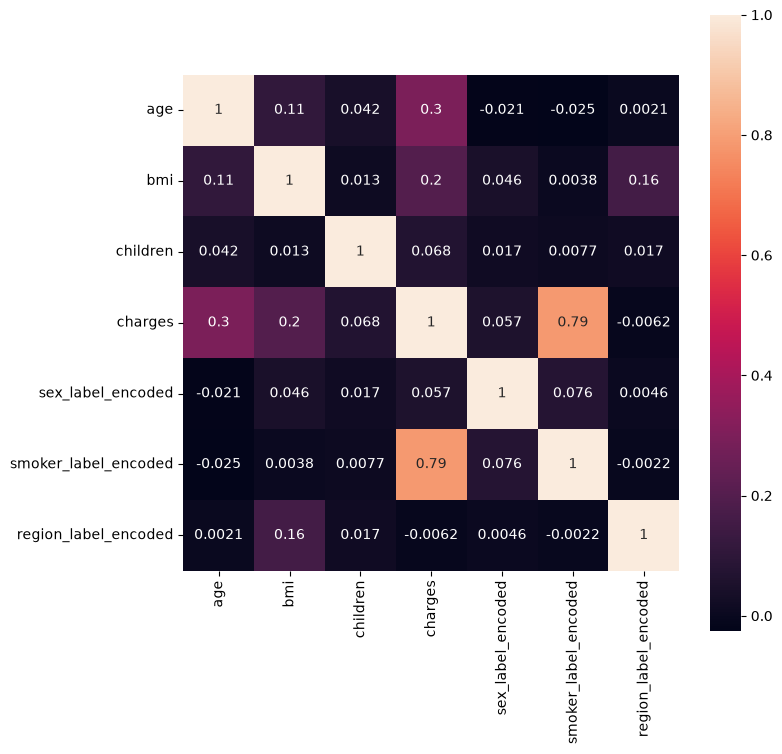

In [362]:
corr_matrix = df.corr(method='pearson', numeric_only=True)
plt.figure(figsize = (8, 8))
sns.heatmap(data=corr_matrix, square=True , annot=True, cbar=True)
plt.show()

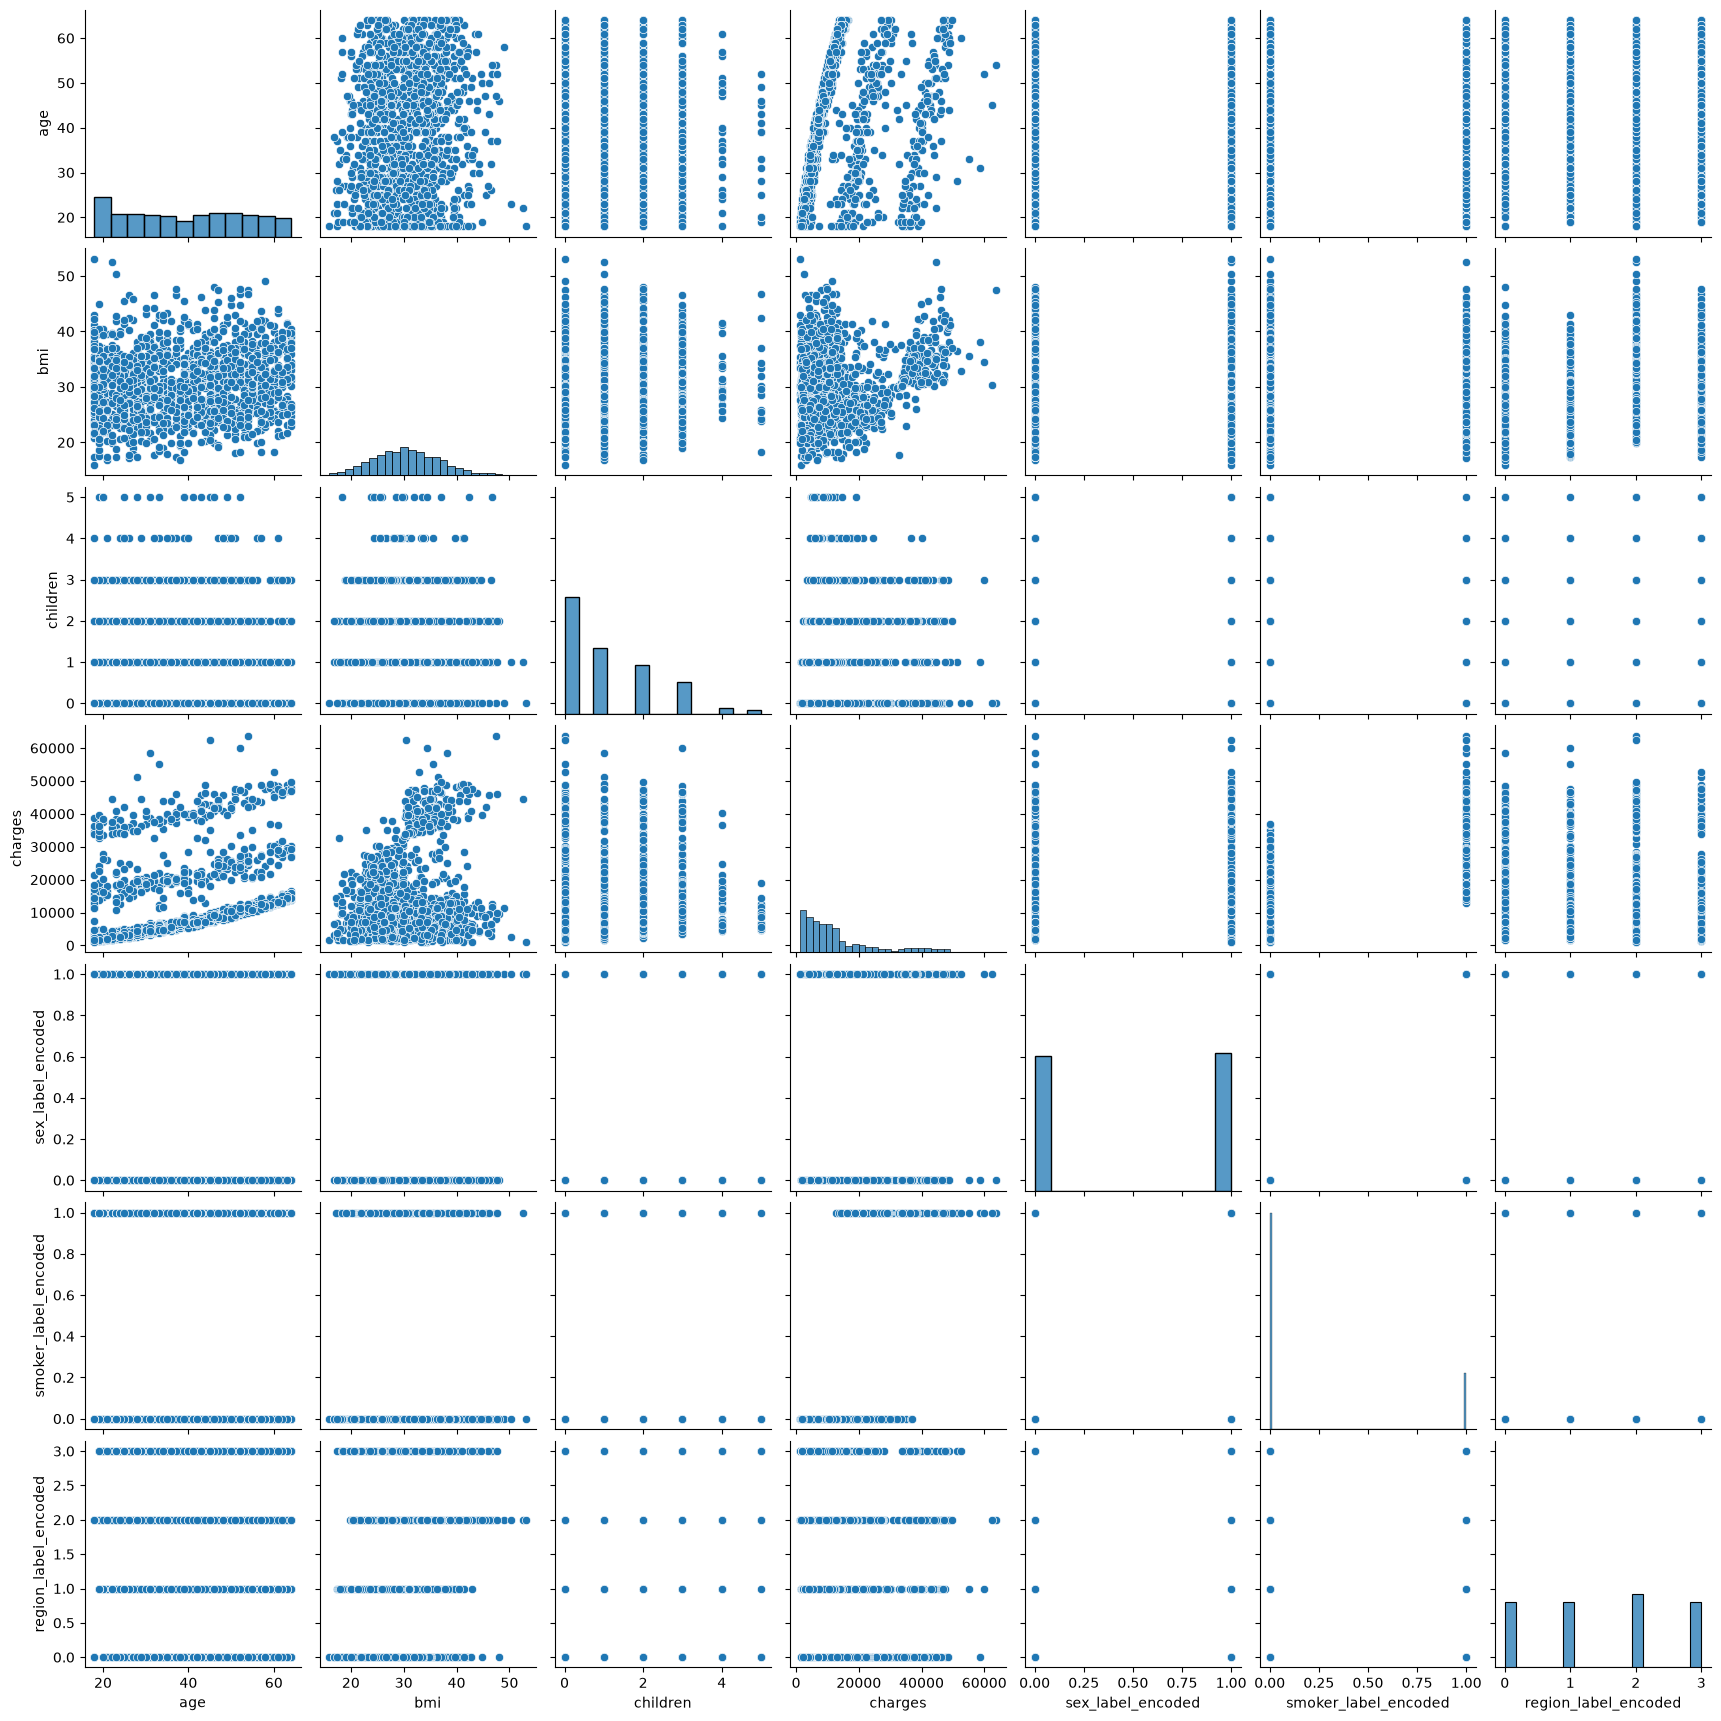

In [363]:
sns.pairplot(df)

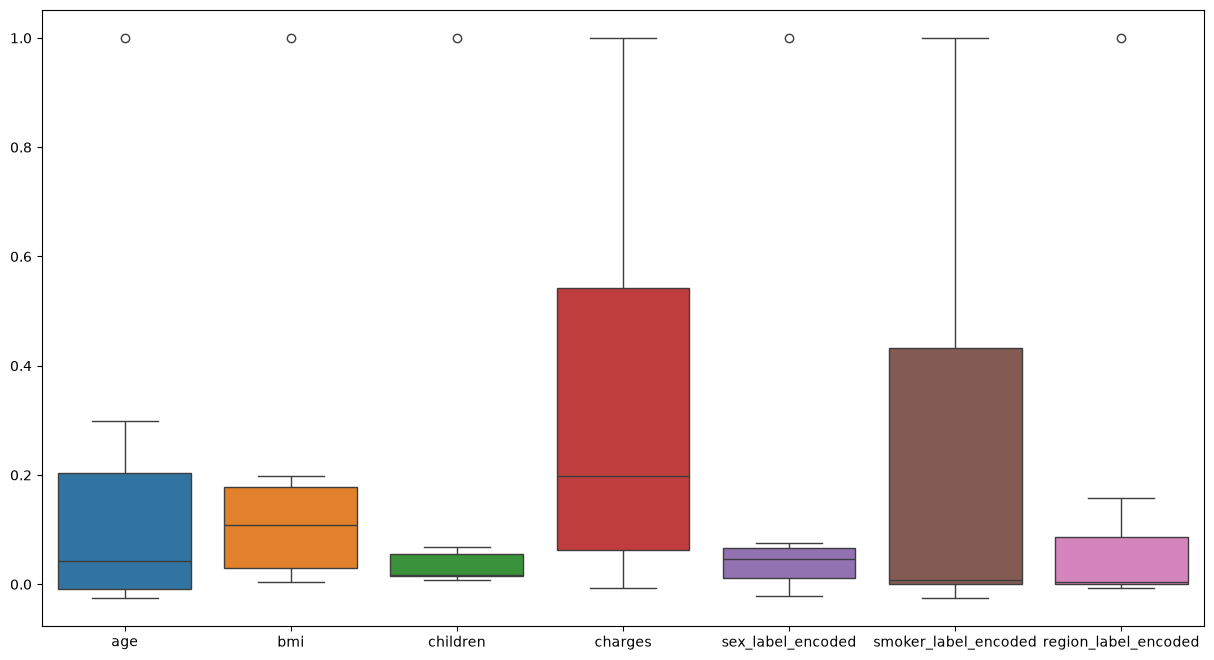

In [364]:
corr_matrix = df.corr(method='pearson', numeric_only=True)
plt.figure(figsize = (15, 8))
sns.boxplot(data=corr_matrix)
plt.show()

In [365]:
df.head()

,age,sex,bmi,children,smoker,region,charges,sex_label_encoded,smoker_label_encoded,region_label_encoded
0,19,female,27.900,0,yes,southwest,16884.92400,0,1,3
1,18,male,33.770,1,no,southeast,1725.55230,1,0,2
2,28,male,33.000,3,no,southeast,4449.46200,1,0,2
3,33,male,22.705,0,no,northwest,21984.47061,1,0,1
4,32,male,28.880,0,no,northwest,3866.85520,1,0,1


In [366]:
X = df["age"].values.reshape((-1, 1))

In [367]:
X.shape

(1338, 1)

In [368]:
y = df["charges"].values

In [369]:
from sklearn import model_selection
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=66)


In [370]:
type(y_train)

numpy.ndarray

In [371]:
lin_model = linear_model.LinearRegression()
lin_model.fit(X_train, y_train);


In [372]:
y_test_pred = lin_model.predict(X_test)

In [373]:
# prdict smoker
# lin_model.predict([[1]])

In [374]:
print("R^2: {:.4f}".format(lin_model.score(X_train, y_train)))
print("R^2: {:.4f}".format(lin_model.score(X_test, y_test)))

R^2: 0.0901
R^2: 0.0819


Text(0.5, 1.0, 'Plot of risuduals')

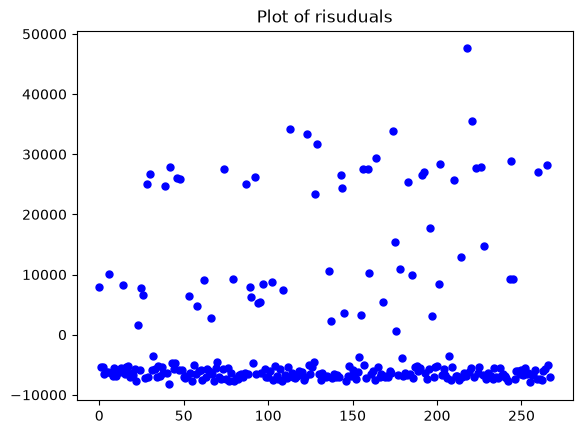

In [375]:
plt.plot(y_test-y_test_pred, color='b', ls='-', lw='0', marker='.', markersize='10')
plt.title('Plot of risuduals')

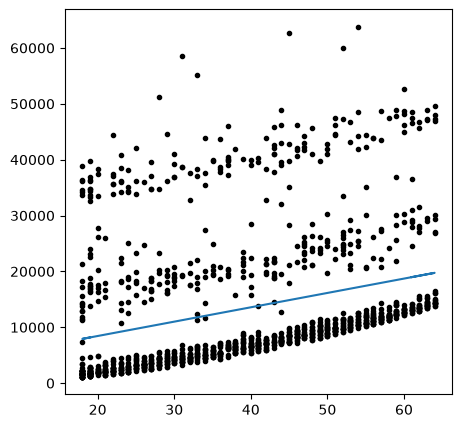

In [376]:
plt.figure(figsize=(5, 5))
plt.plot(X, y, '.k')
plt.plot(X, lin_model.predict(X))

In [377]:
X_mul = df[['age', 'bmi', 'smoker_label_encoded', 'children']]
X_mul.shape

(1338, 4)

In [378]:
X_mul_train, X_mul_test, y_mul_train, y_mul_test = model_selection.train_test_split(X_mul, y, test_size=0.2, random_state=66)

mul_lin_model = linear_model.LinearRegression()
mul_lin_model.fit(X_mul_train, y_mul_train)

mul_lin_model_predict = mul_lin_model.predict(X_mul_test)

In [379]:
print("R^2: {:.4f}".format(mul_lin_model.score(X_mul_train, y_mul_train)))
print("R^2: {:.4f}".format(mul_lin_model.score(X_mul_test, y_mul_test)))

R^2: 0.7407
R^2: 0.7800


In [380]:
def adjusted_r_square(model, X, y):
    coefficient = (X.shape[0]-1) / (X.shape[0]-X.shape[1]-1)
    return (1 - (1-model.score(X, y)) * coefficient)

print(f'Adjusted R^2={adjusted_r_square(mul_lin_model, X_mul_test, y_mul_test)}')


Adjusted R^2=0.7766599241605372


In [381]:
X3 = df[['age', 'smoker_label_encoded', 'children']]
X3.shape

(1338, 3)

In [382]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X3, y, test_size=0.2, random_state=66)

mul2_lin_model = linear_model.LinearRegression()
mul2_lin_model.fit(X_train, y_train)

mul2_model_predict = mul2_lin_model.predict(X_test)

In [383]:
print("R^2: {:.4f}".format(mul2_lin_model.score(X_train, y_train)))
print("R^2: {:.4f}".format(mul2_lin_model.score(X_test, y_test)))

R^2: 0.7118
R^2: 0.7644


In [384]:
print(f'Adjusted R^2={adjusted_r_square(mul2_lin_model, X_test, y_test)}')

Adjusted R^2=0.7617071205065852


In [385]:
df['age_2'] = df['age']**2